# IntroStat Week 2 

Welcome to the second lecture in IntroStat

During the lectures we will present both slides and notebooks. 

This is the notebook used in the lecture in week 2.


In [1]:
import sys
print(sys.executable)

/usr/local/bin/python3


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

### Example 1: Simulation of a discrete stochastic (random) variable (rolling a dice)

In [3]:
result = np.random.choice(range(1,7), size=1)
print(result)

[6]


### Example 2: Simulate n rolls with a fair dice

Consider the stochastic variabel X describing rolling a (fair) dice. 
The f(x) (pdf) is:

| X: |1|2|3|4|5|6|
|:--:|:--:|:--:|:--:|:--:|:--:|:--:|
| f(x): | 1/6 | 1/6 | 1/6 | 1/6 | 1/6 | 1/6 |

In [4]:
# Number of simulated realizations (sample size)
n = 30

# roll dice:
xFair = np.random.choice([1,2,3,4,5,6], size=n, replace=True) # we do not need to specify p if all probabilities are equal
# If we wanted to specify probabilities, we could do it like this:
# xUnFair = np.random.choice([1,2,3,4,5,6], size=n, replace=True, p=[1/7,1/7,1/7,1/7,1/7,2/7])

print(xFair)

[4 3 5 6 2 2 6 4 3 1 1 3 6 3 4 2 2 3 3 6 3 1 1 5 5 2 5 2 3 6]


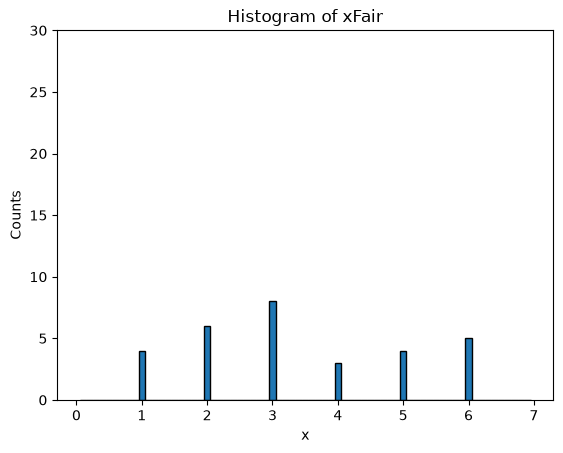

In [5]:
# Plot histogram:
plt.hist(xFair, bins=np.arange(0.05,7,.1),edgecolor='black')
plt.xlabel('x')
plt.ylabel('Counts')
plt.ylim([0,n])
plt.title('Histogram of xFair')
plt.show()

In [6]:
# Count the number of each outcome using the bincount function
counts = np.bincount(xFair)
print(counts)

[0 4 6 8 3 4 5]


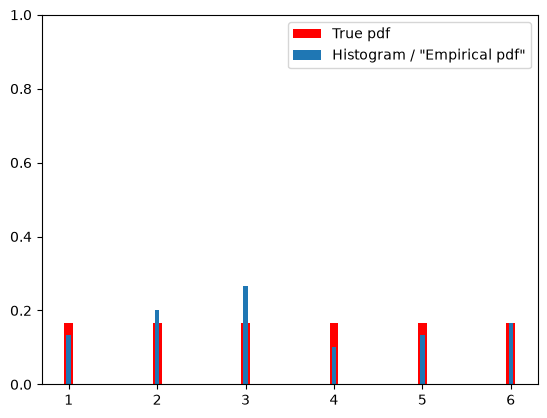

In [7]:
# Plot the true/theoretical pdf 
plt.bar(range(1,7), [1/6]*6, color='red', label='True pdf', width=0.1)

# add the empirical pdf (normalised histogram) to the plot
plt.bar(range(1,7), counts[1:7]/n, width=0.05, label='Histogram / "Empirical pdf"')

# add legend to the plot
plt.legend()

# set limits of y-axis 
plt.ylim([0,1])

# show the plot
plt.show()

### Example 3: Simmulate n rolls with an unfair dice

In [8]:
# Number of simulated realizations (sample size)
n = 30

# roll dice:
probs = [1/7, 1/7, 1/7, 1/7, 1/7, 2/7]
xUnFair = np.random.choice([1,2,3,4,5,6], size=n, replace=True, p=probs)
print(xUnFair)

[6 6 4 4 6 4 4 5 6 4 5 2 6 3 1 6 6 5 3 5 6 2 5 1 5 5 5 6 1 5]


In [9]:
# Count the number of each outcome using the bincount function
counts = np.bincount(xUnFair)
print(counts)

[0 3 2 2 5 9 9]


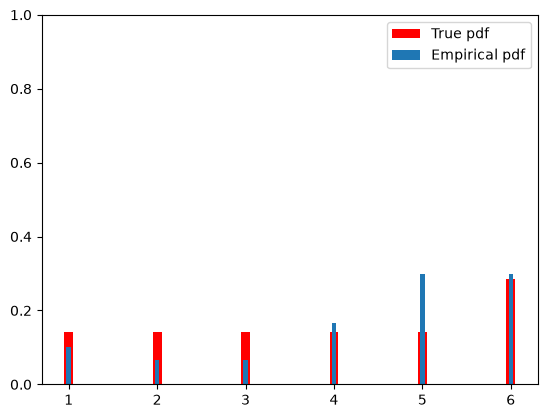

In [10]:
# Plot the true/theoretical pdf 
plt.bar(range(1,7), probs, color='red', label='True pdf', width=0.1)

# add the empirical pdf to the plot
plt.bar(range(1,7), counts[1:7]/n, width=0.05, label='Empirical pdf')


plt.legend()
plt.ylim([0,1])
plt.show()

### Example 4: Empirical Cumulative Distribution Function (ECDF)

In [11]:
# Take the data from the unfair die again
print(xUnFair) # Number of simulated realizations (sample size 30)
print(counts) # Count the number of each outcome , i.e. 1,2,3...,6 using the bincount function

[6 6 4 4 6 4 4 5 6 4 5 2 6 3 1 6 6 5 3 5 6 2 5 1 5 5 5 6 1 5]
[0 3 2 2 5 9 9]


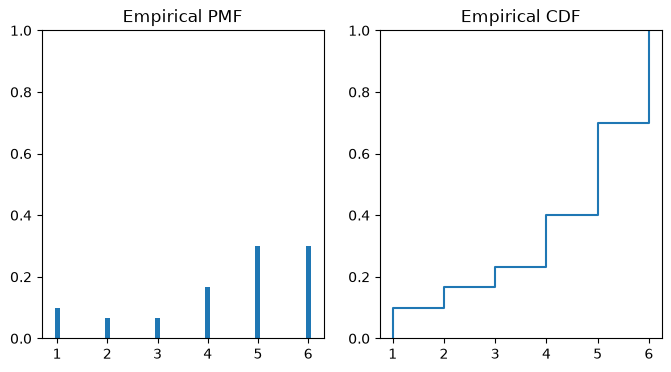

In [12]:
# Plot empirical Probability Mass Function (PMF) and Cumulative Distribution Function (CDF) - Mass Function is used interchangeably with Density function in our book

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8,4))

ax1.bar(range(1,7), counts[1:7]/n, label='True pdf', width=0.1)
ax1.set_ylim([0,1])
ax1.set_title('Empirical PMF')

ax2.ecdf(xUnFair)
ax2.set_ylim([0,1])
ax2.set_title('Empirical CDF')

plt.show()

### Example 5: The binomial distribution

In [13]:
# import scipy.stats for theoretical distributions (and much more)
import scipy.stats as stats

In [14]:
# Probability of "success"
p = 0.1

# Number of repititions
nRepeat = 30

# Simulate Bernoulli experiment 'nRepeat' times
tmp = np.random.choice([0,1], p=[1-p, p], size=nRepeat, replace=True)
print(tmp)

[0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0]


In [15]:
# Calculate number of successes
print(np.sum(tmp))

2


In [16]:
# Or: use the binomial distribution simulation function
stats.binom.rvs(n=nRepeat, p=p) # "rvs" is random variates

3

have a look at documentation for binomial distribution in scipy.stats.binom:
https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binom.html

- .rvs<br>
- .pmf ("pdf" but for discrete distributions)<br>
- .cdf<br>
- .ppf<br>
<br>
and more..

### Example 6: Number of 6's with fair dice

In [17]:
# 'nRepeat' independent draws from the set [1,2,3,4,5,6]
nRepeat = 30
xFair = np.random.choice([1,2,3,4,5,6], size=nRepeat, replace=True)
print(xFair)

# Count number of 6's:
print(np.sum(xFair == 6))

[4 3 6 4 6 1 6 4 6 4 6 5 5 5 3 4 5 6 4 2 6 6 1 2 6 5 5 4 3 5]
9


In [18]:
# Or: use the binomial distribution simulation function
stats.binom.rvs(n=nRepeat, p=1/6)

6

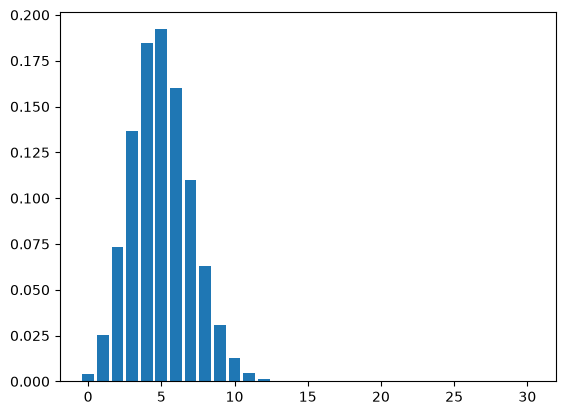

In [19]:
plt.bar(np.arange(0, nRepeat+1, 1), stats.binom.pmf(k=np.arange(0,nRepeat+1,1), n=nRepeat, p=1/6))
plt.show()

### Callcenter example

In [20]:
# we can calculate the probability using the pdf ("pmf") of the binomial:
print(stats.binom.pmf(k=6, n=6, p=0.70))

0.11764899999999996


By hand it would look like, 

$P(X=6)=\begin{pmatrix} 6\\6\end{pmatrix} 0.70^6(1-0.70)^{6-6}=\frac{6!}{6!(6-6)!}0.70^6=0.70^6\approx 0.1176$

The mean and variance for this probability when calculated by hand would look like, 

$\mu = np=6\cdot 0.7 = 4.2$

$\sigma^2= np(1-p)=6\cdot 0.7\cdot(1-0.7)=1.26$

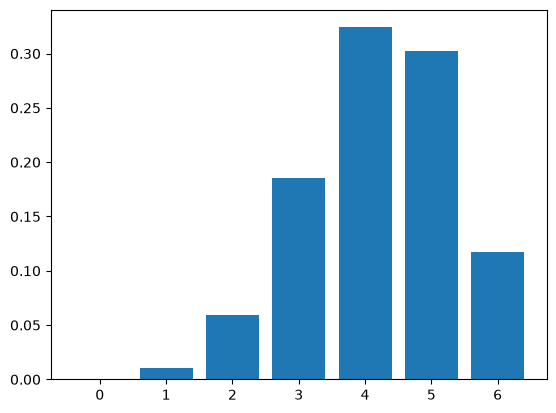

In [21]:
# lets plot entire pdf ("pmf"):
plt.bar(np.arange(0,7,1),stats.binom.pmf(k=np.arange(0,7,1), n=6, p=0.70))
plt.show()

### Harddrive example
Python (scipy.stats) uses different argument names than the book for the many parameters of the Hypergeometric distribution.

In the book we use `n` draws with `a` number of successes from a `N` size population. `(n,a,N)`. Whereas the corresponding Python (scipy.stats) arguments (parameters) would be `(N,n,M)` - so `N` for number of draws, `n` number of successes from a `M` size population.

Additionally, `k` correponds to `x` from the book.


| Meaning | Book | Python| Example values| 
|:--:|:--:|:--:|:--:|
| Number of draws | n | N | 3 |
| Number of successes | a | n | 2 |
| Size population | N | M | 10 | 

In [22]:
# we can calculate the probability using the pdf ("pmf") of the hypergoemetrical distribution:
print(1 - stats.hypergeom.pmf(k=0, M=10, n=2, N=3))

0.5333333333333333


By hand it would look like, 

$1 - P(X=0)=1-\frac{\begin{pmatrix}2\\0\end{pmatrix}\begin{pmatrix}10-2\\3-0\end{pmatrix}}{\begin{pmatrix}10\\3\end{pmatrix}}$

$=1-\frac{\frac{2!}{0!(2-0)!} \frac{8!}{3!(8-3)!}}{\frac{10!}{3!(10-3)!}}=1-\frac{1\cdot\frac{8!}{6!}}{\frac{10!}{3!\cdot 7!}}=1-\frac{8\cdot 7}{\frac{10\cdot 9\cdot8}{6}}$

$=1-\frac{8\cdot 7\cdot 6}{10\cdot 9\cdot 8}=1-\frac{42}{90}=\frac {48}{90}\approx 0.533$

The mean and variance for this probability when calculated by hand would look like, 

$\mu = n\frac aN=3\cdot\frac 2 {10}=0.6$

$\sigma^2= n\frac{1(N-a)}{N^2}\frac{N-n}{N-1}=3\frac{2(10-2)}{10^2}\frac{10-3}{10-1}=\frac{336}{900}=0.373$

### Hospital admission example

In [23]:
# we can calculate the probability using the pdf ("pmf") of the poisson distribution:
print(stats.poisson.pmf(k=0,mu=0.3)+stats.poisson.pmf(k=1,mu=0.3)+stats.poisson.pmf(k=2,mu=0.3))

0.9964005068169105


In [24]:
# or we can use the cumulative distribution function (cdf):
print(stats.poisson.cdf(k=2,mu=0.3))

0.9964005068169105


By hand it would look like, 

$P(x\le 2)=P(X=0)+P(X=1)+P(X=2)$ 

$= \frac{0.3^0}{0!}e^{-0.3} + \frac{0.3^1}{1!}e^{-0.3} + \frac{0.3^2}{2!}e^{-0.3} = e^{-0.3}(1 + 0.3 + \frac{0.09}2)$

$ =1.345 \cdot e^{-0.3} \approx 0.996$

The mean and variance for this probability when calculated by hand would look like, 

$\mu = \lambda = 0.3$

$\sigma^2= \lambda = 0.3$

### Example 7: Sample mean of n rolls with a fair dice

In [25]:
# Number of simulated realizations (sample size)
n = 30

# n independent draws from the set (1,2,3,4,5,6) 
# with equal probability of each outcome
xFair = np.random.choice(range(1, 7), size=n, replace=True)
print(xFair)

# compute the sample mean:
print(xFair.mean())

[1 4 4 6 1 3 4 6 5 4 5 3 1 1 3 4 2 1 4 6 1 6 4 6 1 5 4 2 6 3]
3.533333333333333


Now change n to 1000 and try again (do not print xFair) - what happens?

### Example 8: Sample variance and standard deviation of n rolls with a fair dice 

In [26]:
# Number of simulated realizations (sample size)
n = 30

# n independent draws from the set (1,2,3,4,5,6) 
# with equal probability of each outcome
xFair = np.random.choice(range(1, 7), size=n, replace=True)
print(xFair)

# compute the sample standard deviation:
print(xFair.std(ddof=1))

# compute the sample variance:
print(xFair.var(ddof=1))

[6 3 4 5 2 2 3 1 5 1 5 3 4 1 4 4 6 5 5 4 1 4 1 6 4 4 1 4 4 5]
1.6333450621206846
2.6678160919540232
